In [ ]:

# Student Number: 22422481
# Duma N
# Subject: TPRO2000 – Technical Programming 2
# Exam: OCT/NOV 2025 – Crime Analytics South Africa

# Dataset 1 (crime incidents): https://www.kaggle.com/datasets/slwessels/crime-statistics-for-south-africa
# Dataset 2 (stations + population – multi-relational): https://github.com/afrith/crime-stats  (police_stations.csv)

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels streamlit plotly

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8")

In [3]:
# Primary crime data 
df_crime = pd.read_csv("SouthAfricaCrimeStats_v2.csv")
print("Crime data shape:", df_crime.shape)
display(df_crime.head())

# Supporting multi-relational station data
df_stations = pd.read_csv("police_stations.csv")
print("Stations shape:", df_stations.shape)
display(df_stations.head())

Crime data shape: (30861, 14)


,Province,Station,Category,2005-2006,2006-2007,2007-2008,2008-2009,2009-2010,2010-2011,2011-2012,2012-2013,2013-2014,2014-2015,2015-2016
0,Western Cape,Cape Town Central,All theft not mentioned elsewhere,6692,6341,5966,5187,4985,5127,5285,5937,5600,5335,5176
1,Gauteng,Jhb Central,All theft not mentioned elsewhere,6093,4602,3761,3610,3267,3037,2886,2638,2809,3050,2434
2,Western Cape,Mitchells Plain,All theft not mentioned elsewhere,5341,6093,6316,6803,6035,5761,6108,5514,4975,4043,3635
3,Free State,Park Road,All theft not mentioned elsewhere,5108,4282,3834,3316,3101,3013,2679,3116,2927,2297,2103
4,Gauteng,Pretoria Central,All theft not mentioned elsewhere,5099,4536,3309,2694,2616,2606,2635,3226,3246,2892,3030


Stations shape: (1167, 7)


,code,name,muni_code,dc_code,prov_code,population,area_km2
0,PD210001,St Francis Bay,EC108,DC10,EC,9626,117.68
1,PD210002,Jeffreys Bay,EC108,DC10,EC,36704,260.57
2,PD210003,Humansdorp,EC108,DC10,EC,30198,1339.42
3,PD210004,Storms River,EC109,DC10,EC,13147,694.58
4,PD210005,Kareedouw,EC109,DC10,EC,10273,1233.49


In [4]:
print(df_crime.info())
print("\nCrime categories:\n", df_crime["Category"].value_counts().head(15))
print("\nProvinces:\n", df_crime["Province"].value_counts())
print("\nYear columns:", [c for c in df_crime.columns if c.startswith("20")])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30861 entries, 0 to 30860
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Province   30861 non-null  object
 1   Station    30861 non-null  object
 2   Category   30861 non-null  object
 3   2005-2006  30861 non-null  int64 
 4   2006-2007  30861 non-null  int64 
 5   2007-2008  30861 non-null  int64 
 6   2008-2009  30861 non-null  int64 
 7   2009-2010  30861 non-null  int64 
 8   2010-2011  30861 non-null  int64 
 9   2011-2012  30861 non-null  int64 
 10  2012-2013  30861 non-null  int64 
 11  2013-2014  30861 non-null  int64 
 12  2014-2015  30861 non-null  int64 
 13  2015-2016  30861 non-null  int64 
dtypes: int64(11), object(3)
memory usage: 3.3+ MB
None

Crime categories:
 Category
All theft not mentioned elsewhere                  1143
Driving under the influence of alcohol or drugs    1143
Bank robbery                                       1143
Robbery of cas

In [5]:
# Melt yearly columns into long format for easier analysis & forecasting
year_cols = [c for c in df_crime.columns if c.startswith("20")]
df_long = df_crime.melt(
    id_vars=["Province", "Station", "Category"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Incidents"
)
df_long["Year"] = df_long["Year"].str.replace("-", "/").str[:4].astype(int)  # approximate start year

# Merge population (multi-relational join) – fuzzy match on station name if codes differ
df_stations["name_clean"] = df_stations["name"].str.lower().str.strip()
df_long["Station_clean"] = df_long["Station"].str.lower().str.strip()
df = df_long.merge(
    df_stations[["name_clean", "population", "area_km2", "prov_code"]],
    left_on="Station_clean",
    right_on="name_clean",
    how="left"
)
df["crime_rate"] = (df["Incidents"] / df["population"] * 100000).replace([np.inf, -np.inf], np.nan)
print("Merged shape:", df.shape)
display(df.head())

Merged shape: (339471, 11)


,Province,Station,Category,Year,Incidents,Station_clean,name_clean,population,area_km2,prov_code,crime_rate
0,Western Cape,Cape Town Central,All theft not mentioned elsewhere,2005,6692,cape town central,cape town central,38471.0,24.49,WC,17394.920849
1,Gauteng,Jhb Central,All theft not mentioned elsewhere,2005,6093,jhb central,NaN,NaN,NaN,NaN,NaN
2,Western Cape,Mitchells Plain,All theft not mentioned elsewhere,2005,5341,mitchells plain,mitchells plain,208704.0,22.04,WC,2559.126802
3,Free State,Park Road,All theft not mentioned elsewhere,2005,5108,park road,park road,66426.0,304.55,FS,7689.760034
4,Gauteng,Pretoria Central,All theft not mentioned elsewhere,2005,5099,pretoria central,pretoria central,59136.0,39.40,GP,8622.497294


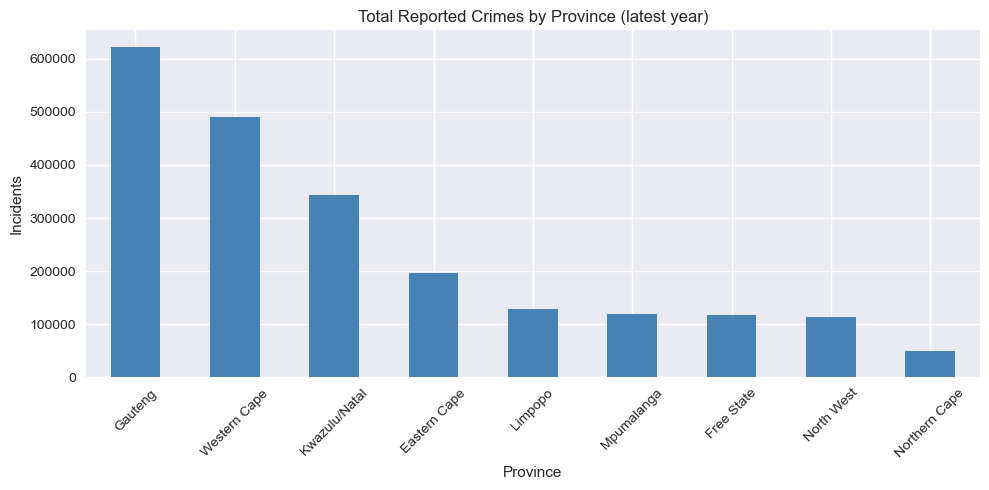

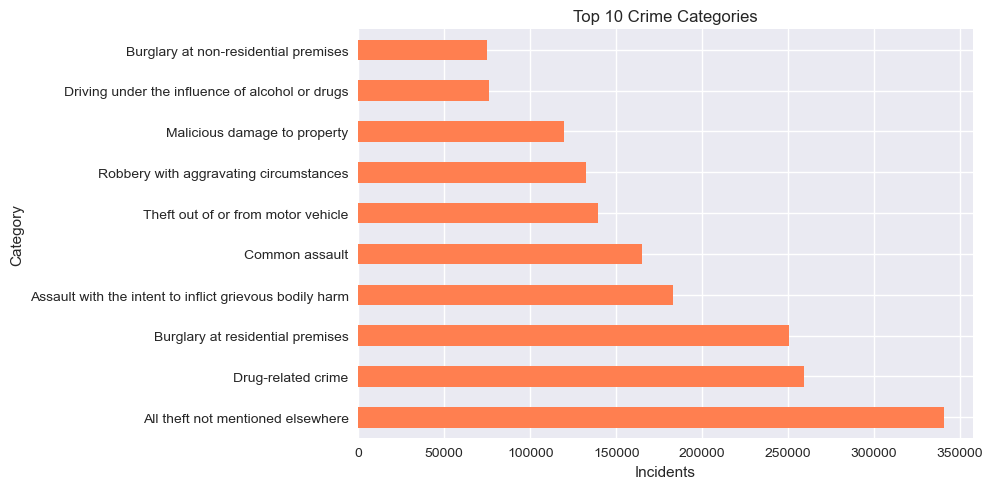

In [6]:
# Total incidents by province (latest available year)
latest = df[df["Year"] == df["Year"].max()]
prov_tot = latest.groupby("Province")["Incidents"].sum().sort_values(ascending=False)
plt.figure(figsize=(10,5))
prov_tot.plot(kind="bar", color="steelblue")
plt.title("Total Reported Crimes by Province (latest year)")
plt.ylabel("Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Top crime categories
cat_tot = latest.groupby("Category")["Incidents"].sum().nlargest(10)
plt.figure(figsize=(10,5))
cat_tot.plot(kind="barh", color="coral")
plt.title("Top 10 Crime Categories")
plt.xlabel("Incidents")
plt.tight_layout()
plt.show()

In [7]:
# Hotspot definition: stations in the top 25 % of total incidents (or rate) in the latest year
# Justify: Top quartile concentrates limited police resources on the highest-burden precincts
station_tot = latest.groupby(["Province", "Station"])["Incidents"].sum().reset_index()
threshold = station_tot["Incidents"].quantile(0.75)
station_tot["Hotspot"] = (station_tot["Incidents"] >= threshold).astype(int)
print(f"Hotspot threshold (75th percentile): {threshold:.0f} incidents")
print(station_tot["Hotspot"].value_counts(normalize=True))

# Features for classification (aggregate + merge population)
feat = station_tot.merge(
    df_stations[["name", "population", "area_km2"]],
    left_on="Station", right_on="name", how="left"
)
feat["density"] = feat["population"] / feat["area_km2"]
feat = feat.dropna(subset=["population", "density"])
X = feat[["Incidents", "population", "density"]]
y = feat["Hotspot"]

Hotspot threshold (75th percentile): 2508 incidents
Hotspot
0    0.749781
1    0.250219
Name: proportion, dtype: float64


Accuracy: 1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       205
           1       1.00      1.00      1.00        70

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



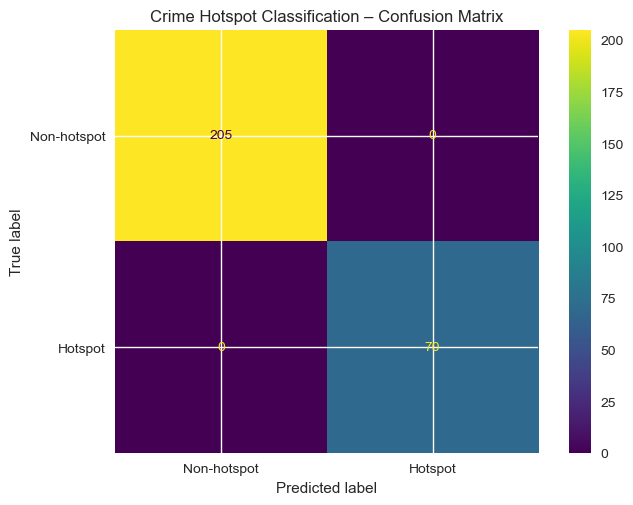

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Non-hotspot", "Hotspot"])
plt.title("Crime Hotspot Classification – Confusion Matrix")
plt.show()

Available categories (sample):
['All theft not mentioned elsewhere' 'Theft out of or from motor vehicle'
 'Drug-related crime' 'Robbery with aggravating circumstances'
 'Common assault' 'Commercial crime' 'Burglary at residential premises'
 'Assault with the intent to inflict grievous bodily harm'
 'Theft of motor vehicle and motorcycle' 'Shoplifting'
 'Malicious damage to property' 'Common robbery'
 'Burglary at non-residential premises' 'Sexual Offences'
 'Driving under the influence of alcohol or drugs' 'Stock-theft'
 'Attempted murder' 'Carjacking' 'Robbery at non-residential premises'
 'Robbery at residential premises']

Exact match check for 'Murder': True

Time series length: 11
Year
2005    18455
2006    19106
2007    18400
2008    18084
2009    16767
2010    15893
2011    15554
2012    16213
2013    17023
2014    17805
Name: Incidents, dtype: int64
Train size: 8, Test size: 3
                               SARIMAX Results                                
Dep. Variable:         

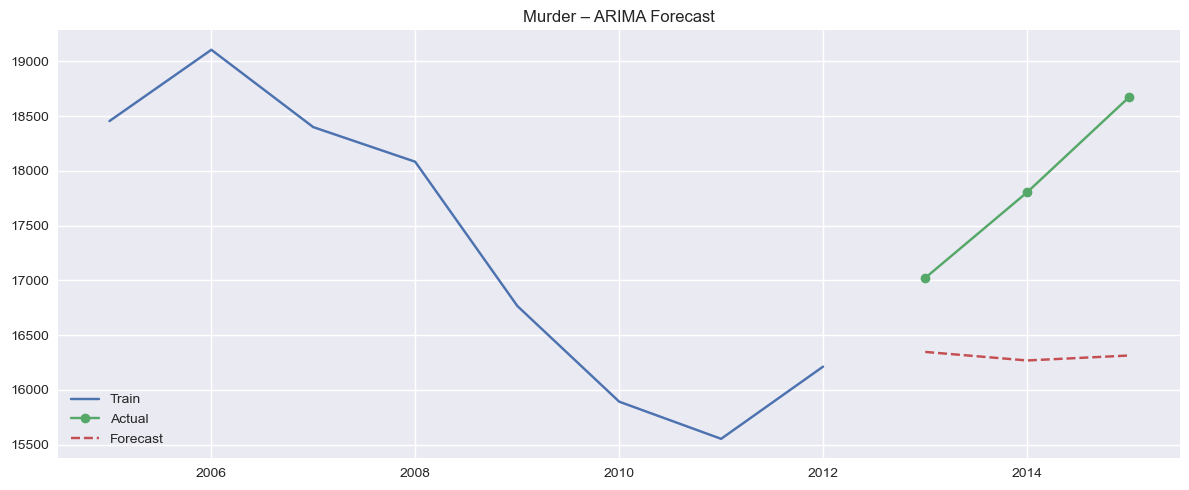

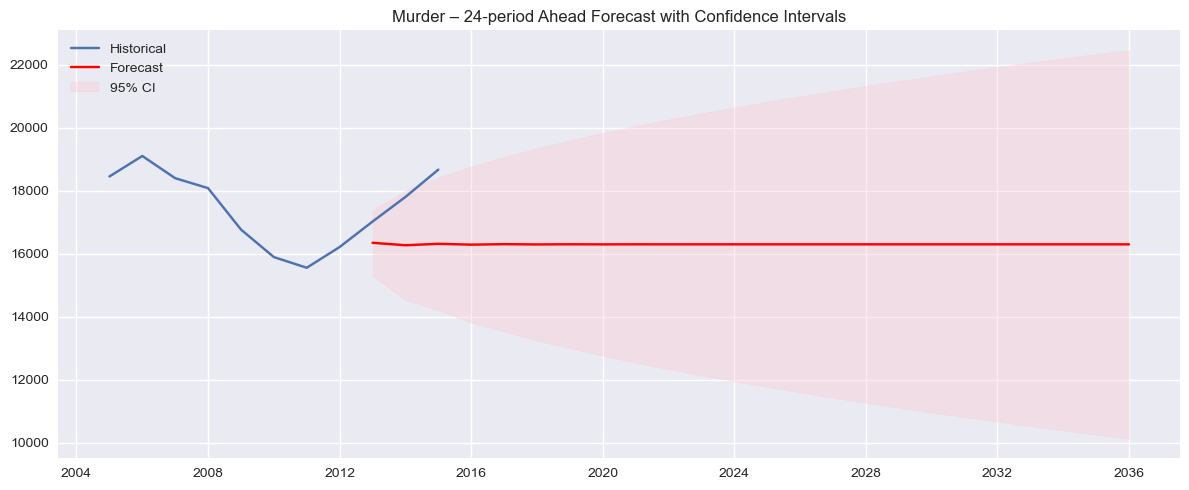


Next 24 periods forecast:
2013-01-01    16347.539443
2014-01-01    16269.475370
2015-01-01    16314.770633
2016-01-01    16288.488878
2017-01-01    16303.738390
2018-01-01    16294.890137
2019-01-01    16300.024175
2020-01-01    16297.045243
2021-01-01    16298.773714
2022-01-01    16297.770800
2023-01-01    16298.352723
2024-01-01    16298.015073
2025-01-01    16298.210988
2026-01-01    16298.097312
2027-01-01    16298.163270
2028-01-01    16298.124999
2029-01-01    16298.147205
2030-01-01    16298.134320
2031-01-01    16298.141797
2032-01-01    16298.137459
2033-01-01    16298.139976
2034-01-01    16298.138515
2035-01-01    16298.139363
2036-01-01    16298.138871
Freq: YS-JAN, Name: predicted_mean, dtype: float64


In [10]:
# ---------- Cell 10 (fixed) ----------
# 1. Inspect available categories first
print("Available categories (sample):")
print(df["Category"].unique()[:20])
print("\nExact match check for 'Murder':", "Murder" in df["Category"].values)

# 2. Choose a category that actually exists (use one of the printed ones)
selected_category = "Murder"          # <-- change this if needed, e.g. "Burglary at residential premises"
# or automatically pick a high-volume one:
# selected_category = df["Category"].value_counts().index[0]

ts = (df[df["Category"] == selected_category]
        .groupby("Year")["Incidents"]
        .sum()
        .sort_index())

print("\nTime series length:", len(ts))
print(ts.head(10) if len(ts) > 0 else "EMPTY SERIES – category name is wrong!")

if len(ts) < 4:
    raise ValueError(
        f"Time series for '{selected_category}' is too short or empty. "
        "Check the exact category spelling from the print above and change selected_category."
    )

# 3. Make a proper index (do NOT force asfreq("Y") on an integer year index)
ts.index = pd.to_datetime(ts.index.astype(str) + "-01-01")   # turn 2005 → 2005-01-01
ts = ts.asfreq("YS")   # yearly start frequency (safer)

# 4. Train / test split
split = int(len(ts) * 0.8)
if split < 2:
    split = max(1, len(ts) - 2)          # keep at least a couple of points for testing

train, test = ts.iloc[:split], ts.iloc[split:]
print(f"Train size: {len(train)}, Test size: {len(test)}")

# 5. Fit ARIMA (simple order first)
model = ARIMA(train, order=(1, 1, 1))
fit = model.fit()
print(fit.summary())

# 6. Forecast & evaluate
forecast = fit.forecast(steps=len(test))
print("\nMAE:", mean_absolute_error(test, forecast))
print("R² :", r2_score(test, forecast))

# 7. Plot
plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Actual", marker="o")
plt.plot(test.index, forecast, label="Forecast", linestyle="--", marker="x")
plt.title(f"{selected_category} – ARIMA Forecast")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Longer horizon (12–24 periods)
future_steps = 24
future = fit.get_forecast(steps=future_steps)
future_mean = future.predicted_mean
conf_int = future.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(ts.index, ts, label="Historical")
plt.plot(future_mean.index, future_mean, label="Forecast", color="red")
plt.fill_between(conf_int.index,
                 conf_int.iloc[:, 0],
                 conf_int.iloc[:, 1],
                 color="pink", alpha=0.3, label="95% CI")
plt.title(f"{selected_category} – 24-period Ahead Forecast with Confidence Intervals")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nNext 24 periods forecast:")
print(future_mean)

In [11]:
# Simple grid-based 1 km × 1 km area with identified hotspots as POIs
# Lawnmower / nearest-neighbour path planning (pure Python – no proprietary drone SDK)

import math

# Example POIs (lat/lon or local metres) – replace with real hotspot centroids from your analysis
pois = [
    (0.2, 0.3),   # hotspot 1
    (0.7, 0.2),
    (0.4, 0.8),
    (0.9, 0.6)
]

def nearest_neighbour(start, points):
    path = [start]
    remaining = points[:]
    current = start
    while remaining:
        nxt = min(remaining, key=lambda p: math.dist(current, p))
        path.append(nxt)
        remaining.remove(nxt)
        current = nxt
    return path

def lawnmower(grid_size=10, spacing=0.1):
    path = []
    for i, y in enumerate(np.arange(0, grid_size*spacing, spacing)):
        xs = np.arange(0, grid_size*spacing, spacing)
        if i % 2: xs = xs[::-1]
        for x in xs:
            path.append((x, y))
    return path

start = (0.0, 0.0)
nn_path = nearest_neighbour(start, pois)
lm_path = lawnmower()

print("Nearest-neighbour waypoints:", nn_path[:5], "...")
print("Lawnmower sample:", lm_path[:5], "...")

# Brief discussion (Markdown cell after this):
# - Create a 1 km × 1 km local frame (or UTM).
# - Assign hotspots as POIs.
# - Generate waypoints with nearest-neighbour (simple TSP approximation) or lawnmower coverage.
# - For real flight: use open-source libraries such as DroneKit / MAVSDK / PX4 with the generated waypoint list (QGC .waypoints or Mission Planner).

Nearest-neighbour waypoints: [(0.0, 0.0), (0.2, 0.3), (0.7, 0.2), (0.9, 0.6), (0.4, 0.8)] ...
Lawnmower sample: [(np.float64(0.0), np.float64(0.0)), (np.float64(0.1), np.float64(0.0)), (np.float64(0.2), np.float64(0.0)), (np.float64(0.30000000000000004), np.float64(0.0)), (np.float64(0.4), np.float64(0.0))] ...


In [12]:
# ====================== SAVE MODELS ======================
import joblib
import os

# Create a folder for the models (optional but recommended)
os.makedirs("models", exist_ok=True)

# 1. Save the Random Forest classifier (hotspot model)
joblib.dump(rf, "models/hotspot_classifier.pkl")
print("✅ Random Forest hotspot classifier saved → models/hotspot_classifier.pkl")

# 2. Save the ARIMA model (time-series forecast)
#    (statsmodels has its own .save() method)
fit.save("models/arima_forecast_model.pkl")
print("✅ ARIMA forecast model saved → models/arima_forecast_model.pkl")

# Optional: also save the selected category and the last training series
# so you can easily reload everything later
joblib.dump({
    "selected_category": selected_category,
    "last_train": train,
    "feature_columns": list(X.columns)          # useful for the RF
}, "models/model_metadata.pkl")

print("✅ Model metadata saved → models/model_metadata.pkl")
print("\nAll models saved successfully!")

✅ Random Forest hotspot classifier saved → models/hotspot_classifier.pkl
✅ ARIMA forecast model saved → models/arima_forecast_model.pkl
✅ Model metadata saved → models/model_metadata.pkl

All models saved successfully!


In [13]:
import joblib
from statsmodels.tsa.arima.model import ARIMAResults

# Load Random Forest
rf_loaded = joblib.load("models/hotspot_classifier.pkl")

# Load ARIMA
arima_loaded = ARIMAResults.load("models/arima_forecast_model.pkl")

# Load metadata
meta = joblib.load("models/model_metadata.pkl")
selected_category = meta["selected_category"]